# 00. Подготовка данных

| Датасет | Для чего | Что хранится на Drive |
| --- | --- | --- |
| Golos (test) | речь с расшифровками для модуля 1 | ~1 ГБ |
| MUSAN (noise, music) | фон для смесей | до 2 ГБ |
| Dusha (Hugging Face) | эмоции, модуль 2 | 2–4 ГБ |
| Speech Commands v0.02 | короткие слова, модуль 3 | ~0,3 ГБ (10 слов) |

**T4 GPU**

In [6]:
from google.colab import drive
drive.mount('/content/drive')

REPO = 'https://github.com/tanyalebedeva/call-audio-analysis.git'
!test -d /content/call-audio-analysis || git clone -q $REPO /content/call-audio-analysis
%cd /content/call-audio-analysis
!git pull -q
!pip install -q -r requirements.txt

DATA = '/content/drive/MyDrive/coursework/data'
RUNS = '/content/drive/MyDrive/coursework/runs'
!mkdir -p $DATA $RUNS
!nvidia-smi --query-gpu=name,memory.total --format=csv || echo 'GPU не подключён: Среда выполнения → Сменить среду → T4 GPU'

Mounted at /content/drive
/content/call-audio-analysis
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
name, memory.total [MiB]
Tesla T4, 15360 MiB


In [ ]:
import os, json
DATA = '/content/drive/MyDrive/coursework/data'
RUNS = '/content/drive/MyDrive/coursework/runs'
print('--- манифесты ---')
for f in sorted(os.listdir(f'{DATA}/manifests')):
    n = sum(1 for _ in open(f'{DATA}/manifests/{f}', encoding='utf-8'))
    print(f'{f:32s} {n}')
print('--- прогоны ---')
if os.path.exists(RUNS):
    for r in sorted(os.listdir(RUNS)):
        p = f'{RUNS}/{r}/metrics.jsonl'
        ep = sum(1 for _ in open(p)) if os.path.exists(p) else 0
        print(f'{r:28s} эпох: {ep}  best.pt: {os.path.exists(f"{RUNS}/{r}/best.pt")}')
r = json.loads(open(f'{DATA}/manifests/speech_train.jsonl', encoding='utf-8').readline())
print('text у Golos:', repr(r['text']))

--- манифесты ---
commands_test.jsonl              4074
commands_train.jsonl             30769
commands_val.jsonl               3703
dusha_windows_train.jsonl        19564
dusha_windows_val.jsonl          1948
emotion_test.jsonl               4000
emotion_train.jsonl              21600
emotion_val.jsonl                2400
noise_test.jsonl                 123
noise_train.jsonl                984
noise_val.jsonl                  123
speech_test.jsonl                1191
speech_train.jsonl               9528
speech_val.jsonl                 1191
--- прогоны ---
emo_hubert_frozen_ce         эпох: 0  best.pt: False
emo_mel_ce                   эпох: 0  best.pt: False
emo_mel_focal                эпох: 0  best.pt: False
vae_mse                      эпох: 0  best.pt: False
text у Golos: 'запусти сериал не родись красивой'


In [ ]:
import json
for s in ['train', 'val', 'test']:
    p = f'{DATA}/manifests/speech_{s}.jsonl'
    rows = [json.loads(l) for l in open(p, encoding='utf-8')]
    for r in rows:
        r['text'] = r.get('text') or ''
    with open(p, 'w', encoding='utf-8') as f:
        f.writelines(json.dumps(r, ensure_ascii=False) + '\n' for r in rows)
    print(s, len(rows), 'всего,', sum(1 for r in rows if r['text']), 'с текстом')

train 9528 всего, 9450 с текстом
val 1191 всего, 1180 с текстом
test 1191 всего, 1181 с текстом


In [ ]:
import json, os
M = f'{DATA}/manifests'
for f in sorted(os.listdir(M)):
    n = sum(1 for _ in open(f'{M}/{f}', encoding='utf-8'))
    print(f'{f:32s} {n}')
r = [json.loads(l) for l in open(f'{M}/speech_train.jsonl', encoding='utf-8')]
print(r[:2])
!grep -n "Error\|error" {RUNS}/../night.log | tail -5
!tail -15 {RUNS}/../night.log

dusha_windows_train.jsonl        19564
dusha_windows_val.jsonl          1948
emotion_test.jsonl               4000
emotion_train.jsonl              21600
emotion_val.jsonl                2400
noise_test.jsonl                 123
noise_train.jsonl                984
noise_val.jsonl                  123
speech_test.jsonl                1191
speech_train.jsonl               9528
speech_val.jsonl                 1191
[{'path': '/content/drive/MyDrive/coursework/data/golos/crowd/008258.flac', 'duration': 3.38, 'text': 'запусти сериал не родись красивой', 'domain': 'crowd'}, {'path': '/content/drive/MyDrive/coursework/data/golos/crowd/004265.flac', 'duration': 2.378, 'text': '', 'domain': 'crowd'}]
grep: /content/drive/MyDrive/coursework/runs/../night.log: No such file or directory
tail: cannot open '/content/drive/MyDrive/coursework/runs/../night.log' for reading: No such file or directory


## Проверка кода на синтетике
За ~1 минуту проверяет, что обучение, чекпойнты и метрики работают в этой среде.

In [ ]:
!python -m pytest -q

.................                                                        [100%]


## 1. Golos - речь с расшифровками

In [ ]:
!python -m callaudio.data.prepare golos --out $DATA

[download] https://sc.link/Kqr
  ошибка: скачано 0 из 0 байт
[golos] архив недоступен: Не удалось скачать https://sc.link/Kqr: скачано 0 из 0 байт
[golos] crowd: 9994 записей
[golos] farfield: 1916 записей
[manifest] speech_test.jsonl: 1191 записей, 1.26 ч
[manifest] speech_val.jsonl: 1191 записей, 1.26 ч
[manifest] speech_train.jsonl: 9528 записей, 10.08 ч


## 2. MUSAN - шум и музыка
Архив ~11 ГБ скачивается во временную папку Colab, на Drive кладётся только нужное.

In [ ]:
!python -m callaudio.data.prepare musan --out $DATA --music-files 300

  0.6 / 10.3 ГБ
  0.8 / 10.3 ГБ
  1.0 / 10.3 ГБ
  1.2 / 10.3 ГБ
  1.4 / 10.3 ГБ
  1.6 / 10.3 ГБ
  1.8 / 10.3 ГБ
  2.0 / 10.3 ГБ
  2.1 / 10.3 ГБ
  2.3 / 10.3 ГБ
  2.5 / 10.3 ГБ
  2.7 / 10.3 ГБ
  2.9 / 10.3 ГБ
  3.1 / 10.3 ГБ
  3.3 / 10.3 ГБ
  3.5 / 10.3 ГБ
  3.7 / 10.3 ГБ
  3.9 / 10.3 ГБ
  4.1 / 10.3 ГБ
  4.3 / 10.3 ГБ
  4.5 / 10.3 ГБ
  4.7 / 10.3 ГБ
  4.9 / 10.3 ГБ
  5.1 / 10.3 ГБ
  5.3 / 10.3 ГБ
  5.5 / 10.3 ГБ
  5.7 / 10.3 ГБ
  5.9 / 10.3 ГБ
  6.1 / 10.3 ГБ
  6.2 / 10.3 ГБ
  6.4 / 10.3 ГБ
  6.6 / 10.3 ГБ
  6.8 / 10.3 ГБ
  7.0 / 10.3 ГБ
  7.2 / 10.3 ГБ
  7.4 / 10.3 ГБ
  7.6 / 10.3 ГБ
  7.8 / 10.3 ГБ
  8.0 / 10.3 ГБ
  8.2 / 10.3 ГБ
  8.4 / 10.3 ГБ
  8.6 / 10.3 ГБ
  8.8 / 10.3 ГБ
  9.0 / 10.3 ГБ
  9.2 / 10.3 ГБ
  9.4 / 10.3 ГБ
  9.6 / 10.3 ГБ
  9.8 / 10.3 ГБ
  10.0 / 10.3 ГБ
  10.2 / 10.3 ГБ
[extract] musan: noise и music (это несколько минут)
/content/call-audio-analysis/callaudio/data/prepare.py:151: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and r

## 3. Dusha - эмоции
6000 записей на класс в train (если в классе меньше - берутся все) и 1000 в test.

In [ ]:
!python -m callaudio.data.prepare dusha --out $DATA --per-class 6000 --test-per-class 1000

README.md: 100% 473/473 [00:00<00:00, 1.59MB/s]
Resolving data files: 100% 48/48 [00:00<00:00, 22153.01it/s]
  train: {'angry': 427, 'neutral': 1026, 'positive': 327, 'sad': 220}
  train: {'angry': 857, 'neutral': 2064, 'positive': 664, 'sad': 415}
  train: {'angry': 1286, 'neutral': 3106, 'positive': 1003, 'sad': 605}
  train: {'angry': 1716, 'neutral': 4190, 'positive': 1319, 'sad': 775}
  train: {'angry': 2130, 'neutral': 5250, 'positive': 1651, 'sad': 969}
  train: {'angry': 2706, 'neutral': 6000, 'positive': 2073, 'sad': 1221}
  train: {'angry': 3620, 'neutral': 6000, 'positive': 2766, 'sad': 1614}
  train: {'angry': 4545, 'neutral': 6000, 'positive': 3459, 'sad': 1996}
  train: {'angry': 5436, 'neutral': 6000, 'positive': 4168, 'sad': 2396}
  train: {'angry': 6000, 'neutral': 6000, 'positive': 5126, 'sad': 2874}
  train: {'angry': 6000, 'neutral': 6000, 'positive': 6000, 'sad': 4000}


## 4. Окна Dusha по 1 с - для VAE на русской речи (модуль 3 → признаки для модуля 2)

In [ ]:
!python -m callaudio.data.prepare dusha_windows --out $DATA

Traceback (most recent call last):
  File "<frozen runpy>", line 203, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/content/call-audio-analysis/callaudio/data/prepare.py", line 367, in <module>
    main()
    ~~~~^^
  File "/content/call-audio-analysis/callaudio/data/prepare.py", line 359, in main
    prepare_dusha_windows(a.out)
    ~~~~~~~~~~~~~~~~~~~~~^^^^^^^
  File "/content/call-audio-analysis/callaudio/data/prepare.py", line 306, in prepare_dusha_windows
    result.append({"path": str(path), "duration": save_flac(seg, path), "label": r["label"]})
                                                  ~~~~~~~~~^^^^^^^^^^^
  File "/content/call-audio-analysis/callaudio/data/prepare.py", line 78, in save_flac
    sf.write(str(path), wav, SAMPLE_RATE, format="FLAC")
    ~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/soundfile.py", line 375, in write
    with SoundFile(file, 'w', samplerate, channels,
  

## 5. Speech Commands - короткие слова для VAE

In [ ]:
!python -m callaudio.data.prepare commands --out $DATA --words core

[skip] уже скачано: /content/work/speech_commands_v0.02.tar.gz
[manifest] commands_train.jsonl: 30769 записей, 8.55 ч
[manifest] commands_val.jsonl: 3703 записей, 1.03 ч
[manifest] commands_test.jsonl: 4074 записей, 1.13 ч


## 6. Анализ данных - графики для главы 2 записки

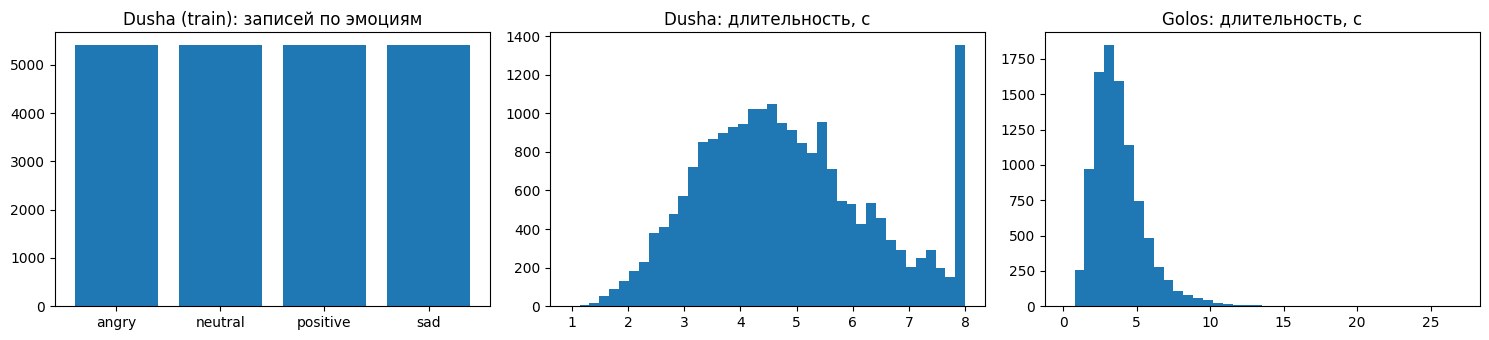

dusha_windows_train.jsonl          19564 записей    5.43 ч
dusha_windows_val.jsonl             1948 записей    0.54 ч
emotion_test.jsonl                  4000 записей    5.33 ч
emotion_train.jsonl                21600 записей   28.91 ч
emotion_val.jsonl                   2400 записей    3.16 ч
noise_test.jsonl                     123 записей    2.59 ч
noise_train.jsonl                    984 записей   20.38 ч
noise_val.jsonl                      123 записей    2.64 ч
speech_test.jsonl                   1191 записей    1.26 ч
speech_train.jsonl                  9528 записей   10.08 ч
speech_val.jsonl                    1191 записей    1.26 ч


In [ ]:
import json, collections, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
M = Path(DATA) / 'manifests'
def load(name): return [json.loads(l) for l in open(M / name, encoding='utf-8')]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
emo = load('emotion_train.jsonl')
cnt = collections.Counter(r['label'] for r in emo)
axes[0].bar(cnt.keys(), cnt.values()); axes[0].set_title('Dusha (train): записей по эмоциям')
axes[1].hist([r['duration'] for r in emo], bins=40); axes[1].set_title('Dusha: длительность, с')
speech = load('speech_train.jsonl')
axes[2].hist([r['duration'] for r in speech], bins=40); axes[2].set_title('Golos: длительность, с')
plt.tight_layout(); plt.savefig(f'{DATA}/data_overview.png', dpi=150); plt.show()
for name in sorted(p.name for p in M.glob('*.jsonl')):
    rows = load(name)
    print(f"{name:32s} {len(rows):7d} записей  {sum(r.get('duration', 0) for r in rows) / 3600:6.2f} ч")

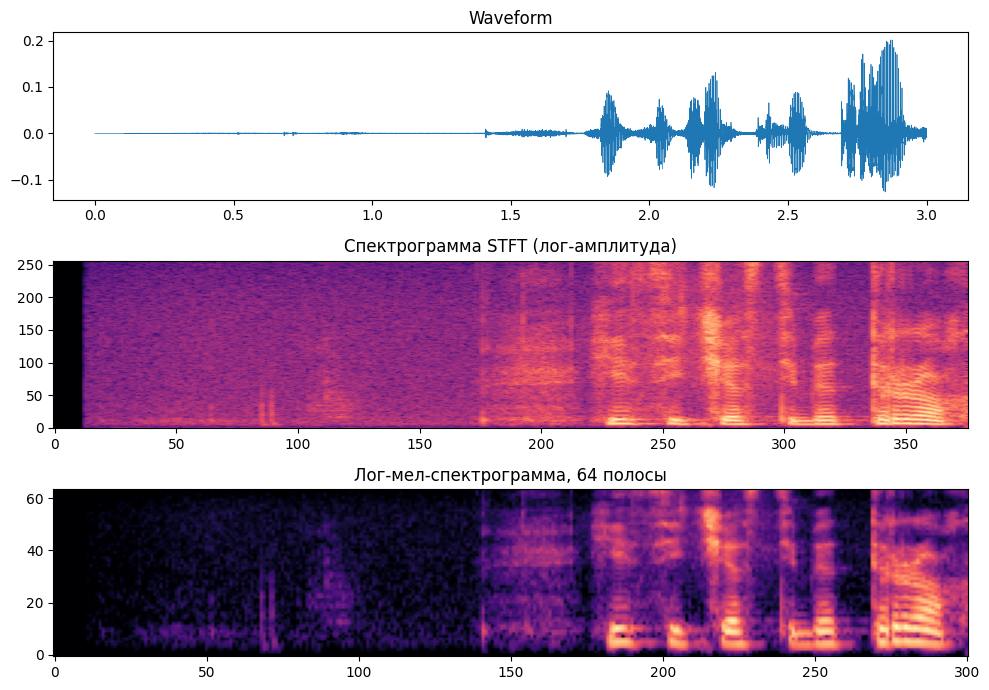

In [ ]:
import torch
from callaudio.audio import load_audio, LogMel, EMOTION_MEL, vocoder_mel
row = next(r for r in emo if r['label'] == 'angry')
wav = load_audio(row['path'])[:16000 * 3]
fig, axes = plt.subplots(3, 1, figsize=(10, 7))
axes[0].plot(np.arange(len(wav)) / 16000, wav, lw=0.5); axes[0].set_title('Waveform')
spec = torch.stft(torch.from_numpy(wav), 512, 128, window=torch.hann_window(512), return_complex=True).abs()
axes[1].imshow(torch.log(spec + 1e-5), origin='lower', aspect='auto', cmap='magma'); axes[1].set_title('Спектрограмма STFT (лог-амплитуда)')
axes[2].imshow(LogMel(EMOTION_MEL)(torch.from_numpy(wav)[None])[0], origin='lower', aspect='auto', cmap='magma'); axes[2].set_title('Лог-мел-спектрограмма, 64 полосы')
plt.tight_layout(); plt.savefig(f'{DATA}/representations.png', dpi=150); plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!test -d /content/call-audio-analysis || git clone -q https://github.com/tanyalebedeva/call-audio-analysis.git /content/call-audio-analysis
%cd /content/call-audio-analysis
!git checkout -q -- . && git pull -q
!pip install -q -r requirements.txt

def patch(path, old, new):
    s = open(path, encoding='utf-8').read()
    if old in s:
        open(path, 'w', encoding='utf-8').write(s.replace(old, new, 1))
        print('исправлено:', path)

patch('callaudio/audio.py', "        wav = _load_with_ffmpeg(path, sr)\n",
      "        try:\n            wav = _load_with_ffmpeg(path, sr)\n        except Exception:\n            print(f'[audio] пропуск битого файла {path}', flush=True)\n            wav = np.zeros(int((duration or 1.0) * sr), dtype=np.float32)\n")
patch('callaudio/data/prepare.py', 'text = ex.get("transcription", ex.get("text", ""))',
      'text = ex.get("transcription") or ex.get("text") or ""')
patch('callaudio/data/datasets.py', 'return wav, row.get("text", "")', 'return wav, row.get("text") or ""')
!python -c "import callaudio.tasks; print('код в порядке')"

import os
LOCAL = '/content/data'
RUNS = '/content/drive/MyDrive/coursework/runs'
os.makedirs(RUNS, exist_ok=True)
ip = get_ipython()
LOG = f'{RUNS}/../night.log'
def run(cmd):
    print('\n>>>', cmd, flush=True)
    ip.system(f'{cmd} 2>&1 | tee -a {LOG}')

run(f'python -m callaudio.data.prepare commands --out {LOCAL} --words core')
run(f'python -m callaudio.data.prepare golos --out {LOCAL}')
run(f'python -m callaudio.data.prepare musan --out {LOCAL} --music-files 300')
run(f'python -m callaudio.data.prepare dusha --out {LOCAL} --per-class 6000 --test-per-class 1000')

D = f'data_root={LOCAL}'
plan = [
    ('configs/separation/unet_sisdr.yaml',   'epochs=12', 45),
    ('configs/emotion/mel_cnn.yaml',         'epochs=12', 35),
    ('configs/emotion/mel_cnn.yaml',         f'epochs=12 loss.name=focal out_dir={RUNS}/emo_mel_focal', 35),
    ('configs/emotion/hubert_frozen.yaml',   'epochs=6', 50),
    ('configs/vae/vae_mse.yaml',             'epochs=25', 25),
    ('configs/vae/cvae.yaml',                'epochs=25', 25),
    ('configs/separation/tasnet_sisdr.yaml', 'epochs=12', 60),
    ('configs/emotion/mel_cnn.yaml',         f'epochs=12 loss.name=weighted_ce out_dir={RUNS}/emo_mel_weighted_ce', 30),
    ('configs/vae/vae_beta4.yaml',           'epochs=25', 25),
]
for cfg, sets, minutes in plan:
    run(f'python -m callaudio.train --config {cfg} --set {D} {sets} max_minutes={minutes}')

ENH = f'{RUNS}/sep_unet_sisdr/best.pt'
for r in ['sep_unet_sisdr', 'sep_tasnet_sisdr']:
    run(f'python -m callaudio.evaluate separation --ckpt {RUNS}/{r}/best.pt --limit 300 --wer --whisper small')
for r in ['emo_mel_ce', 'emo_mel_focal', 'emo_mel_weighted_ce', 'emo_hubert_frozen_ce']:
    run(f'python -m callaudio.evaluate emotion --ckpt {RUNS}/{r}/best.pt')
    run(f'python -m callaudio.evaluate emotion --ckpt {RUNS}/{r}/best.pt --noise-snr 5')
    run(f'python -m callaudio.evaluate emotion --ckpt {RUNS}/{r}/best.pt --noise-snr 5 --enhancer {ENH}')
for r in ['vae_mse', 'vae_beta4', 'cvae_mse']:
    run(f'python -m callaudio.evaluate vae --ckpt {RUNS}/{r}/best.pt --pair yes,no')
run(f'python -m callaudio.viz --run {RUNS}/emo_mel_ce')
run(f'python -m callaudio.report --runs {RUNS} --out {RUNS}/../reports')
print('ГОТОВО')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/call-audio-analysis
исправлено: callaudio/audio.py
исправлено: callaudio/data/prepare.py
исправлено: callaudio/data/datasets.py
код в порядке

>>> python -m callaudio.data.prepare commands --out /content/data --words core
/content/call-audio-analysis/callaudio/data/prepare.py:259: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall(extract_dir)
[download] http://download.tensorflow.org/data/speech_commands_v0.02.tar.gz
  0.2 / 2.3 ГБ
  0.4 / 2.3 ГБ
  0.6 / 2.3 ГБ
  0.8 / 2.3 ГБ
  1.0 / 2.3 ГБ
  1.2 / 2.3 ГБ
  1.4 / 2.3 ГБ
  1.6 / 2.3 ГБ
  1.8 / 2.3 ГБ
  2.0 / 2.3 ГБ
  2.1 / 2.3 ГБ
[extract] speech commands
[manifest] commands_train.jsonl: 30769 записей, 8.55 ч
[manifest] commands_val.jsonl: 3703 записей, 1.03 ч
[mani

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/call-audio-analysis
!git checkout -q -- . && git pull -q
!pkill -f callaudio || true

def patch(path, old, new):
    s = open(path, encoding='utf-8').read()
    if old in s:
        open(path, 'w', encoding='utf-8').write(s.replace(old, new, 1))
        print('исправлено:', path)
patch('callaudio/audio.py', "        wav = _load_with_ffmpeg(path, sr)\n",
      "        try:\n            wav = _load_with_ffmpeg(path, sr)\n        except Exception:\n            print(f'[audio] пропуск битого файла {path}', flush=True)\n            wav = np.zeros(int((duration or 1.0) * sr), dtype=np.float32)\n")
patch('callaudio/data/prepare.py', 'text = ex.get("transcription", ex.get("text", ""))',
      'text = ex.get("transcription") or ex.get("text") or ""')
patch('callaudio/data/datasets.py', 'return wav, row.get("text", "")', 'return wav, row.get("text") or ""')
!python -c "import callaudio.tasks; print('код в порядке')"

import os, shutil
LOCAL = '/content/data'
M = f'{LOCAL}/manifests'
RUNS = '/content/drive/MyDrive/kursovaya_runs'
os.makedirs(f'{RUNS}/sep_unet_sisdr', exist_ok=True)
old = '/content/drive/MyDrive/coursework/runs/sep_unet_sisdr/best.pt'
if not os.path.exists(f'{RUNS}/sep_unet_sisdr/best.pt'):
    shutil.copy(old, f'{RUNS}/sep_unet_sisdr/best.pt')
    print('U-Net скопирована')

ip = get_ipython()
LOG = f'{RUNS}/log.txt'
def run(cmd):
    print('\n>>>', cmd, flush=True)
    ip.system(f'PYTHONUNBUFFERED=1 {cmd} 2>&1 | tee -a {LOG}')

need = {'commands': 'commands_train.jsonl', 'dusha': 'emotion_test.jsonl',
        'golos': 'speech_test.jsonl', 'musan': 'noise_test.jsonl'}
args = {'commands': '--words core', 'dusha': '--per-class 6000 --test-per-class 1000',
        'golos': '', 'musan': '--music-files 300'}
for name in ['commands', 'dusha']:
    if not os.path.exists(f'{M}/{need[name]}'):
        run(f'python -m callaudio.data.prepare {name} --out {LOCAL} {args[name]}')
print('манифесты:', sorted(os.listdir(M)))

D = f'data_root={LOCAL} log_every=20'
plan = [
    ('configs/emotion/mel_cnn.yaml',       f'epochs=8 out_dir={RUNS}/emo_mel_ce', 25),
    ('configs/vae/vae_mse.yaml',           f'epochs=15 out_dir={RUNS}/vae_mse', 12),
    ('configs/vae/cvae.yaml',              f'epochs=15 out_dir={RUNS}/cvae_mse', 12),
    ('configs/emotion/mel_cnn.yaml',       f'epochs=8 loss.name=focal out_dir={RUNS}/emo_mel_focal', 25),
    ('configs/emotion/hubert_frozen.yaml', f'epochs=3 out_dir={RUNS}/emo_hubert_frozen_ce', 35),
]
for cfg, sets, minutes in plan:
    run(f'python -m callaudio.train --config {cfg} --set {D} {sets} max_minutes={minutes}')

for name in ['golos', 'musan']:
    if not os.path.exists(f'{M}/{need[name]}'):
        run(f'python -m callaudio.data.prepare {name} --out {LOCAL} {args[name]}')

ENH = f'{RUNS}/sep_unet_sisdr/best.pt'
run(f'python -m callaudio.evaluate separation --ckpt {ENH} --speech-manifest {M}/speech_test.jsonl --noise-manifest {M}/noise_test.jsonl --limit 200 --wer --whisper small')
for r in ['emo_mel_ce', 'emo_mel_focal', 'emo_hubert_frozen_ce']:
    run(f'python -m callaudio.evaluate emotion --ckpt {RUNS}/{r}/best.pt')
for r in ['emo_mel_ce', 'emo_hubert_frozen_ce']:
    run(f'python -m callaudio.evaluate emotion --ckpt {RUNS}/{r}/best.pt --noise-manifest {M}/noise_test.jsonl --noise-snr 5')
    run(f'python -m callaudio.evaluate emotion --ckpt {RUNS}/{r}/best.pt --noise-manifest {M}/noise_test.jsonl --noise-snr 5 --enhancer {ENH}')
for r in ['vae_mse', 'cvae_mse']:
    run(f'python -m callaudio.evaluate vae --ckpt {RUNS}/{r}/best.pt --pair yes,no')
run(f'python -m callaudio.report --runs {RUNS} --out {RUNS}/reports')
print('ГОТОВО')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/call-audio-analysis
^C
исправлено: callaudio/audio.py
исправлено: callaudio/data/prepare.py
исправлено: callaudio/data/datasets.py
код в порядке
манифесты: ['commands_test.jsonl', 'commands_train.jsonl', 'commands_val.jsonl', 'emotion_test.jsonl', 'emotion_train.jsonl', 'emotion_val.jsonl', 'speech_test.jsonl', 'speech_train.jsonl', 'speech_val.jsonl']

>>> python -m callaudio.train --config configs/emotion/mel_cnn.yaml --set data_root=/content/data log_every=20 epochs=8 out_dir=/content/drive/MyDrive/kursovaya_runs/emo_mel_ce max_minutes=25
[train] emotion · MelCNN · параметров 1.35 M (обучаемых 1.35 M) · устройство cuda
  эпоха 1 шаг 20/337 loss=1.4097 acc=0.2969
  эпоха 1 шаг 40/337 loss=1.3812 acc=0.3207
  эпоха 1 шаг 60/337 loss=1.3593 acc=0.3349
  эпоха 1 шаг 80/337 loss=1.3436 acc=0.3469
  эпоха 1 шаг 100/337 loss=1.3317 acc=0.3581
  эпоха 1 ш